# DAY 17 大数定律coding 和几个特殊的数学公式

# 概率与大数定律 coding

In [1]:
import numpy as  np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print('Success!!!')

Success!!!


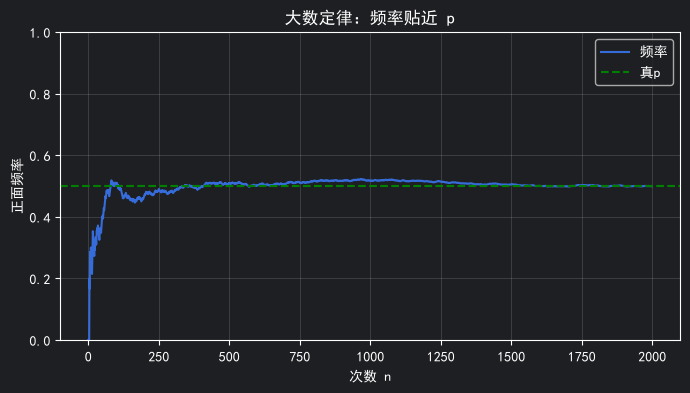

最终频率 0.499


In [2]:
#独立同分布

np.random.seed(0)
p_true = 0.5
N = 2000
flips = np.random.rand(N) < p_true
freq = np.cumsum(flips) / np.arange(1, N+1)

plt.figure(figsize=(8, 4))
plt.plot(freq, label='频率')
plt.axhline(p_true, color='g', ls='--', label='真p')
plt.ylim(0, 1)
plt.xlabel('次数 n')
plt.ylabel('正面频率')
plt.legend()
plt.title('大数定律：频率贴近 p')
plt.grid(True, alpha=0.3)
plt.show()

print('最终频率', freq[-1])

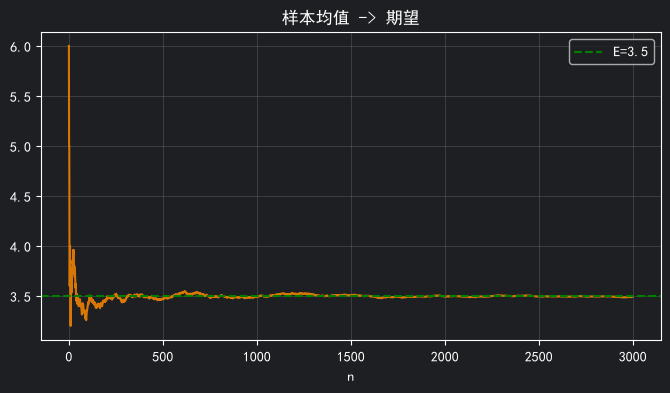

In [4]:
np.random.seed(1)
rolls = np.random.randint(1, 7, size=3000)
means = np.cumsum(rolls) / np.arange(1, len(rolls)+1)

plt.figure(figsize=(8, 4))
plt.plot(means, color='#d97706')
plt.axhline(3.5, color='g', ls='--', label='E=3.5')
plt.xlabel('n')
plt.legend()
plt.title('样本均值 -> 期望')
plt.grid(True, alpha=0.3)
plt.show()

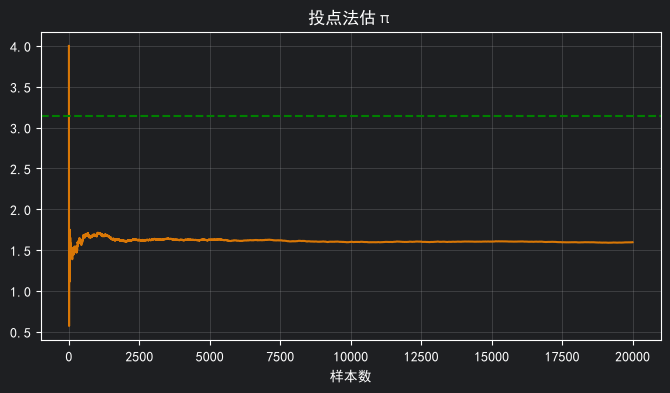

估计π 1.596 真π: 3.141592653589793


In [8]:
# 用蒙特卡洛估计π

np.random.seed(2)
n= 20000
xy = np.random.randn(n, 2)
inside = (xy[:,0]**2 + xy[:,1]**2)<= 1
pi_est = 4*np.cumsum(inside)/np.arange(1, n+1)
plt.figure(figsize=(8, 4))
plt.plot(pi_est, color='#d97706')
plt.axhline(np.pi,color='g', ls='--')
plt.title('投点法估π')
plt.xlabel('样本数')
plt.grid(True, alpha=0.3)
plt.show()
print('估计π',pi_est[-1],'真π:',np.pi)

In [13]:
def mean_spread(n, trails = 500):
    return np.array([(np.random.rand(n) < 0.5).mean() for _ in range(trails)])

for n in [10, 100, 1000]:
    s = mean_spread(n)

    print(f'n={n:4d} 均值的标准差≈{s.std():.4f} (理论≈{0.5/np.sqrt(n):.4f})')

n=  10 均值的标准差≈0.1688 (理论≈0.1581)
n= 100 均值的标准差≈0.0478 (理论≈0.0500)
n=1000 均值的标准差≈0.0167 (理论≈0.0158)


# 几个重要的数学公式

## 注意力机制 (Attention Mechanism)

$$Attention(Q, K, V) = softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

*   **含义**：这是 Transformer 架构中经典的**缩放点积注意力（Scaled Dot-Product Attention）**公式。
*   **变量**：
    *   $Q$ (Query)：查询矩阵
    *   $K$ (Key)：键矩阵
    *   $V$ (Value)：值矩阵
    *   $d_k$：键向量的维度
*   **解释**：先计算 Query 和 Key 的点积（$QK^T$）来衡量相似度，除以 $\sqrt{d_k}$ 防止梯度消失。然后通过 $softmax$ 函数将结果归一化为概率分布（注意力权重），最后与 $V$ 相乘，得到加权求和的输出。

---
积分-微积分方程的离散化形式<br>
非局部积分算子<br>

## Adam优化器参数更新 (Adam Optimizer Update)

$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

*   **含义**：这是 **Adam 优化算法**的核心参数更新公式。
*   **变量**：
    *   $\theta$：模型参数
    *   $\eta$：学习率
    *   $\hat{m}_t$：偏差校正后的一阶矩（梯度均值）
    *   $\hat{v}_t$：偏差校正后的二阶矩（梯度方差）
    *   $\epsilon$：防止分母为 0 的极小常数
*   **解释**：算法通过计算梯度的一阶矩和二阶矩，为不同的参数动态调整学习率（自适应学习率），从而实现更平稳、快速的收敛。

---

### Adam 一阶矩估计 (First Moment Estimate)

$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$

*   **含义**：计算梯度的**指数移动平均（一阶矩，即均值）**。
*   **变量**：
    *   $m_t$：当前时刻的梯度均值估计
    *   $g_t$：当前时刻的梯度
    *   $\beta_1$：衰减率（通常取 0.9）
*   **解释**：它平滑了梯度的波动，保留了历史梯度的趋势，类似于动量（Momentum）法。

---

### Adam 二阶矩估计 (Second Moment Estimate)

$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$

*   **含义**：计算梯度平方的**指数移动平均（二阶矩，即未中心化的方差）**。
*   **变量**：
    *   $v_t$：当前时刻的梯度方差估计
    *   $g_t^2$：当前梯度的平方
    *   $\beta_2$：衰减率（通常取 0.999）
*   **解释**：它记录了梯度变化的剧烈程度，用于在参数更新时对频繁变化的参数给予较小的学习率，对稀疏变化的参数给予较大的学习率。

---
梯度下降是一阶方法，牛顿法是二阶方法<br>
一阶矩（动量）+二阶矩（自适应缩放），实现了“不算H，可达到二阶受凉效果”<br>
深度学习训练的默认优化器<br>
<br>

## 矩阵分解 (Matrix Factorization)与推荐系统：

$$R \approx U V^T$$

*   **含义**：这是推荐系统中常用的**矩阵分解**公式。
*   **变量**：
    *   $R$：用户-物品评分矩阵（通常非常稀疏）
    *   $U$：用户潜在特征矩阵
    *   $V$：物品潜在特征矩阵
*   **解释**：通过将高维稀疏的评分矩阵 $R$ 近似分解为两个低维稠密矩阵 $U$ 和 $V$ 的乘积，来预测用户对未评分物品的偏好。

$$U \in \mathbb{R}^{|U| \times d}, \quad V \in \mathbb{R}^{|I| \times d}$$

*   **含义**：对公式 5 中矩阵维度的具体定义。
*   **变量**：
    *   $|U|$：用户总数
    *   $|I|$：物品总数
    *   $d$：潜在特征向量的维度（通常 $d \ll |U|, |I|$）
*   **解释**：用户矩阵 $U$ 的每一行代表一个用户的 $d$ 维特征向量，物品矩阵 $V$ 的每一行代表一个物品的 $d$ 维特征向量。

---
> **核心要点提炼**
> 线性代数与数值优化（最小化重构误差）
> $R$ 巨大且稀疏，矩阵分解本质是低秩近似。
> 矩阵分解与图神经网络：用图卷积来增强用户和物品的嵌入表？
> 表示：逐层聚合 neighbor（邻居）。

---

### 1. 数学基础：线性代数与数值优化
推荐系统的底层数学工具是**线性代数**。我们通过**数值优化**方法（如梯度下降、交替最小二乘法），去最小化预测评分与真实评分之间的**重构误差**（Reconstruction Error）。

### 2. 核心问题：巨大且稀疏的 $R$ 矩阵

在推荐系统中，用户-物品评分矩阵 $R$（维度为 $|U| \times |I|$）通常**巨大且稀疏**（绝大多数用户只评价过极少数物品，矩阵中大部分是 0）。

*   **矩阵分解（Matrix Factorization, MF）的本质**：就是**低秩近似**。我们将这个高维稀疏矩阵 $R$ 近似分解为两个低维稠密矩阵的乘积：
    $$R \approx U V^T$$
    从而提取出用户和物品的潜在特征（嵌入向量）。

### 3. 进阶演化：矩阵分解与图神经网络的结合

传统矩阵分解只利用了用户和物品之间的直接交互，其局限性在于：无法捕捉用户与用户、物品与物品之间的高阶关联。

*   **用图卷积（GCN）来增强嵌入表**：
    将用户和物品视为图中的节点，交互视为边，构建二部图。
*   **逐层聚合 neighbor（邻居）**：
    GNN 的核心机制。通过图卷积操作，每个用户节点可以聚合其交互过的物品节点信息，物品节点也可以聚合用户节点信息。一层一层传递（逐层聚合），就能捕捉到高阶的协同过滤信号，从而得到更丰富、更准确的用户和物品嵌入表（Embedding）。


## PageRank与图算法 马尔可夫链平稳分布 (Stationary Distribution)

$$\pi P = 1 \cdot \pi$$

*   **含义**：这是马尔可夫链中**平稳分布**的方程（常用于 PageRank 算法）。
*   **变量**：
    *   $P$：状态转移矩阵
    *   $\pi$：平稳分布概率向量
    *   $1$：代表特征值 1（或全 1 向量，视具体记号而定）
*   **解释**：它表示经过一次状态转移（$\pi P$）后，概率分布保持不变，即达到了平稳状态。这意味着 $\pi$ 是转移矩阵 $P$ 对应于特征值 1 的左特征向量。

---

未来只看现在，不看过去 <br>
PageRank 的本质是**在有向图上计算节点的重要性（影响力）**。只要有“关系网络”，就可以用 PageRank（或其变种 Personalised PageRank, PPR）。它的应用场景包括：
*   **社交网络**：识别关键意见领袖（KOL）或寻找社区核心节点。
*   **推荐系统**：将用户和物品构成二部图，通过 PageRank 计算用户对物品的偏好得分。
*   **生物信息学**：在蛋白质相互作用网络中，寻找致病的关键基因。
*   **交通网络**：评估城市路网中各个路口的关键程度。<br>

## 椭圆曲线密码子与后量子密码 线性比例关系 (Linear Relationship)

$$Q = kP$$

*   **含义**：表示变量 $Q$ 与变量 $P$ 之间存在简单的线性正比关系。
*   **变量**：$k$ 是比例常数。
*   **解释**：在具体的算法上下文中（例如图算法或 PageRank 的变体推导中），这可能表示查询向量 $Q$ 是转移矩阵或概率矩阵 $P$ 的 $k$ 倍缩放。具体含义高度依赖于上下文，通常表示某种状态量或查询量的线性变换。

---
ECC 基于ECDLP<br>
后量子密码 同源密码 在两个椭圆之间找到同态映射<br>

## 信号处理：傅里叶变换 (Fourier Transform)

$$\hat{f}(\omega) = \int_{-\infty}^{\infty} f(t) e^{-2\pi i \omega t} dt$$

*   **含义**：这是连续**傅里叶变换**的定义公式。
*   **变量**：
    *   $f(t)$：时域（或空域）信号
    *   $\hat{f}(\omega)$：频域信号
    *   $\omega$：角频率
    *   $i$：虚数单位
*   **解释**：它将信号从时间域转换到频率域，通过积分将信号分解为不同频率的复指数函数的叠加，用于分析信号的频率成分。
*
$$X_k = \sum_{n=0}^{N-1} x_n e^{-2\pi i k n / N}$$

*   **含义**：这是**离散傅里叶变换（Discrete Fourier Transform, DFT）**的定义公式。
*   **变量**：
    *   $X_k$：频域信号的第 $k$ 个分量。
    *   $x_n$：时域（或空域）离散信号的第 $n$ 个采样点。
    *   $N$：采样点的总数（信号长度）。
    *   $e^{-2\pi i k n / N}$：旋转因子（复指数），$i$ 为虚数单位。
*   **解释**：它将长度为 $N$ 的离散时域信号转换到频域，计算出各个频率成分的幅度和相位。

$$O(N^2) \Rightarrow O(N \log N)$$

*   **含义**：这是**快速傅里叶变换（Fast Fourier Transform, FFT）**算法带来的时间复杂度飞跃。
*   **解释**：
    *   如果直接按照上面的定义公式去计算每个 $X_k$（需要做 $N$ 次乘法，共 $N$ 个点），时间复杂度是 $O(N^2)$。
    *   通过 FFT 算法（利用旋转因子的周期性和对称性，采用分治法，如 Cooley-Tukey 算法），可以将复杂度大幅降低到 $O(N \log N)$。这是数字信号处理领域最伟大的算法之一。

---
微积分  复数（欧拉公式） 算法（分治）<br>
时域变换到了频域 本质把信号分解成了不同频率的复指数函数的叠加<br>
分解与逼近<br>